# Section A — Dataset & EDA

## A1 — Dataset Loading & Audit

In [3]:
# Import required libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load dataset
df = pd.read_csv("../data/airline_passenger_satisfaction.csv")

# Display dataset shape
print("Dataset Shape:", df.shape)

# Display data types
print("\nData Types:")
print(df.dtypes)

# Display missing-value counts
print("\nMissing Values:")
print(df.isnull().sum())

# Display target/class distribution
print("\nTarget Distribution:")
print(df["Satisfaction"].value_counts())

Dataset Shape: (129880, 24)

Data Types:
ID                                          int64
Gender                                        str
Age                                         int64
Customer Type                                 str
Type of Travel                                str
Class                                         str
Flight Distance                             int64
Departure Delay                             int64
Arrival Delay                             float64
Departure and Arrival Time Convenience      int64
Ease of Online Booking                      int64
Check-in Service                            int64
Online Boarding                             int64
Gate Location                               int64
On-board Service                            int64
Seat Comfort                                int64
Leg Room Service                            int64
Cleanliness                                 int64
Food and Drink                              int64
In-flight

## A2 — EDA Visualisations

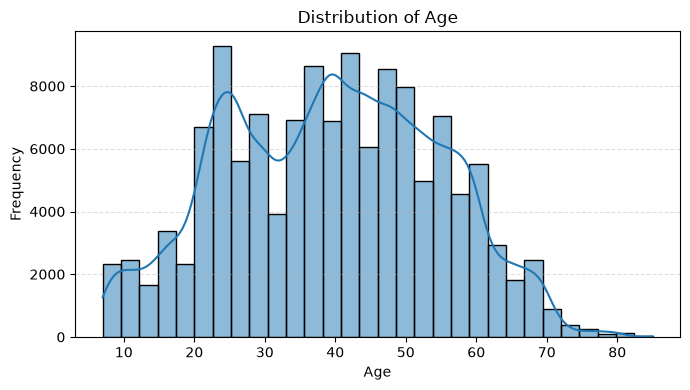

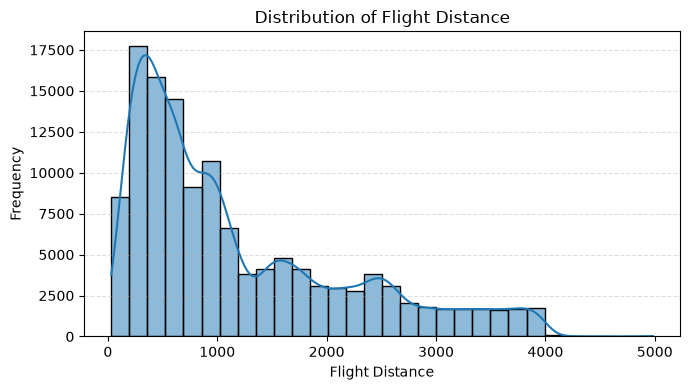

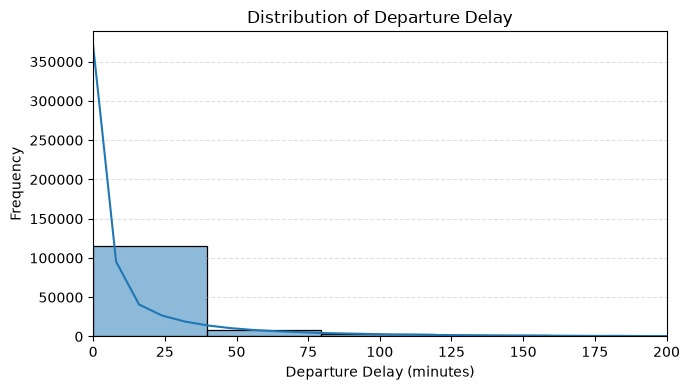

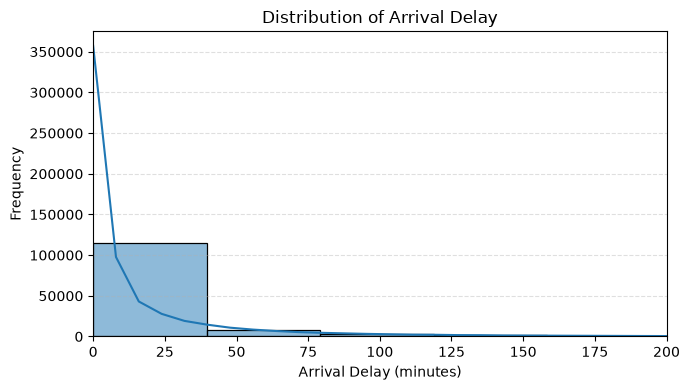

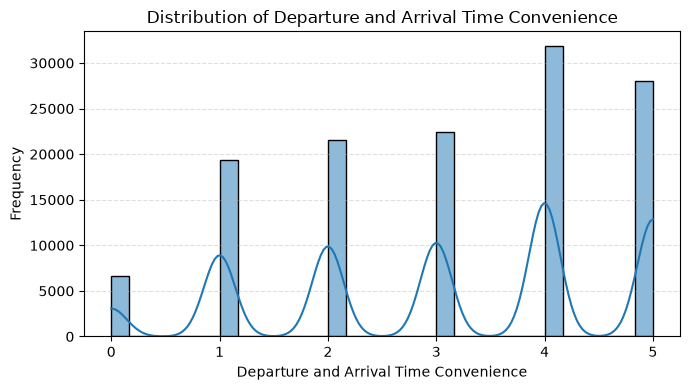

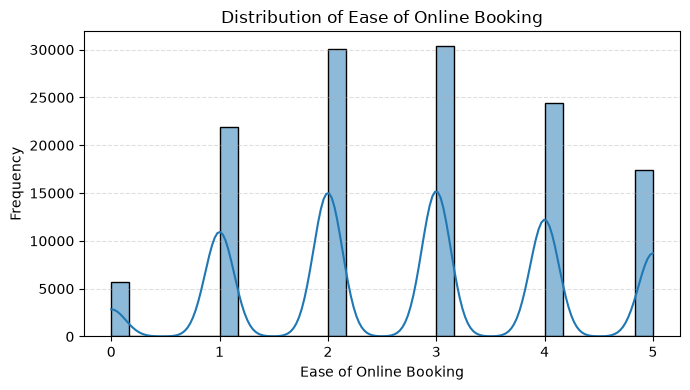

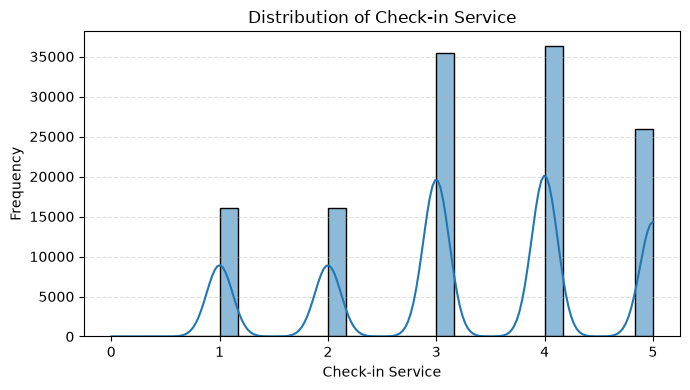

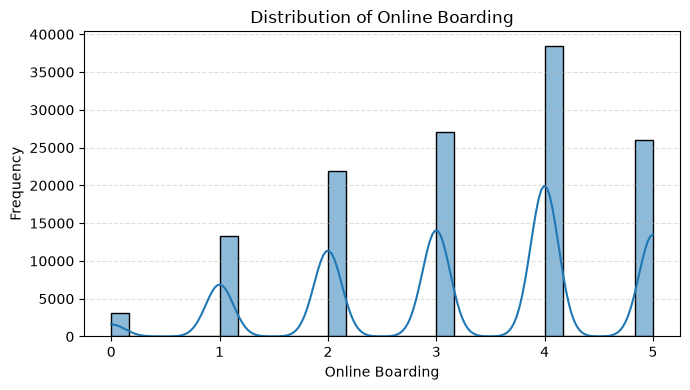

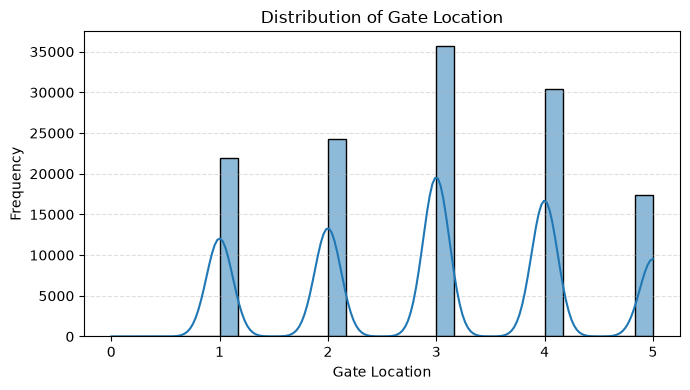

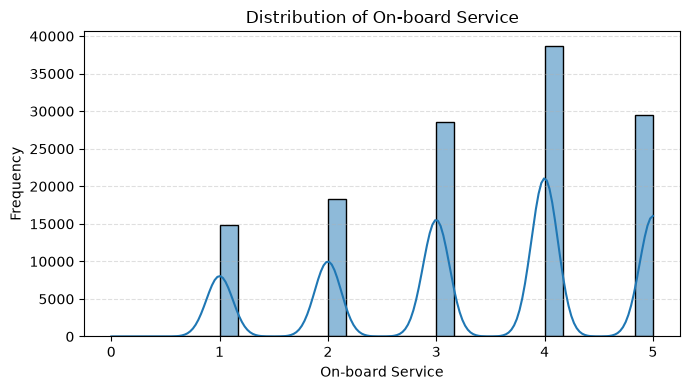

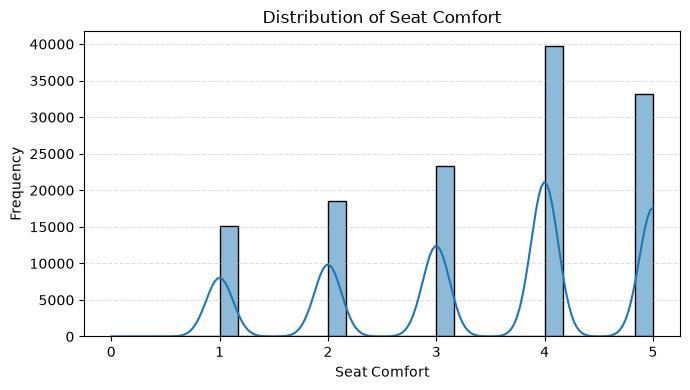

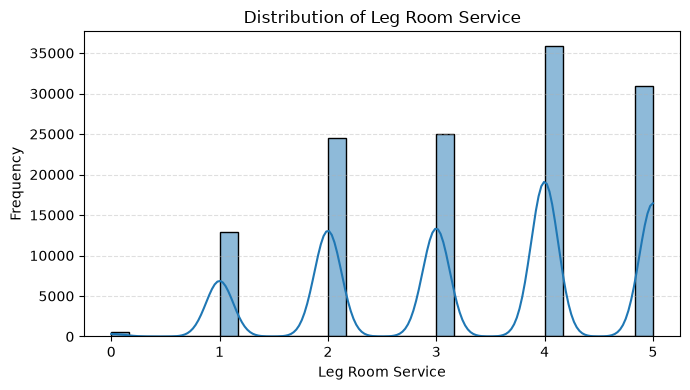

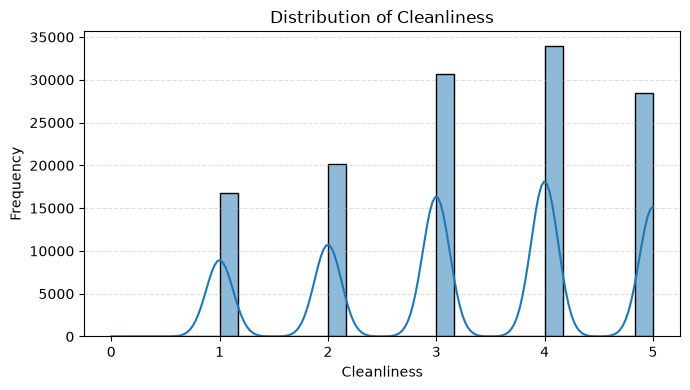

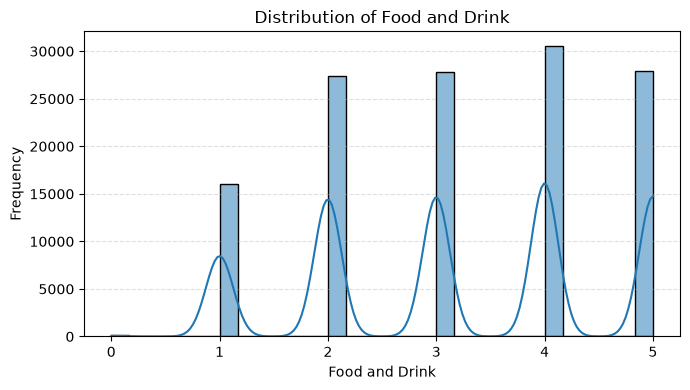

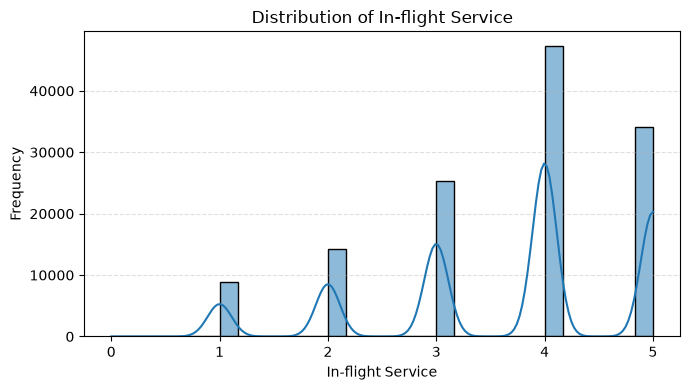

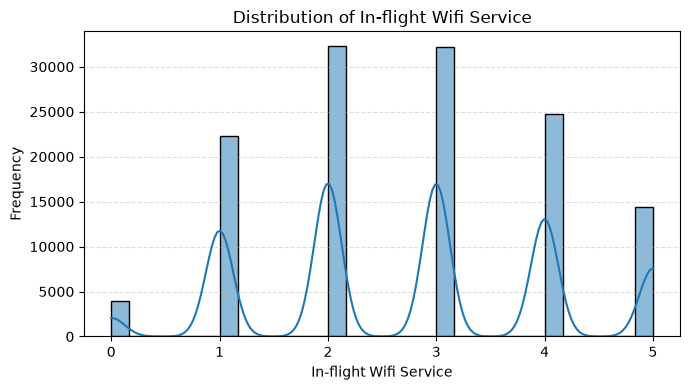

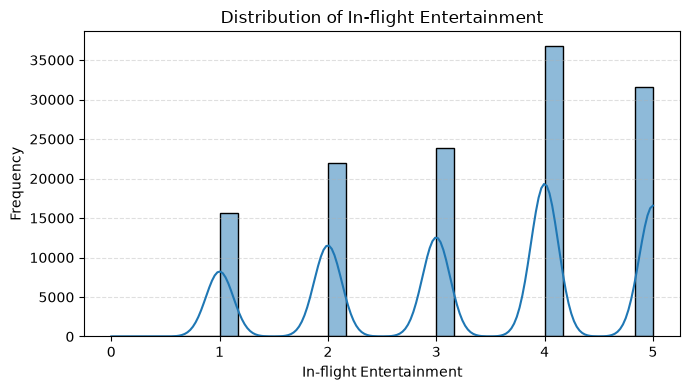

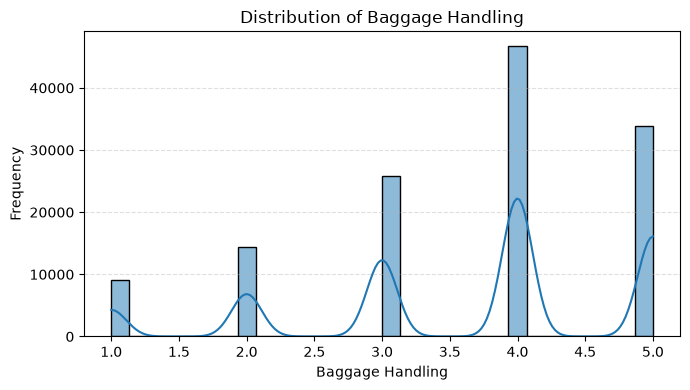

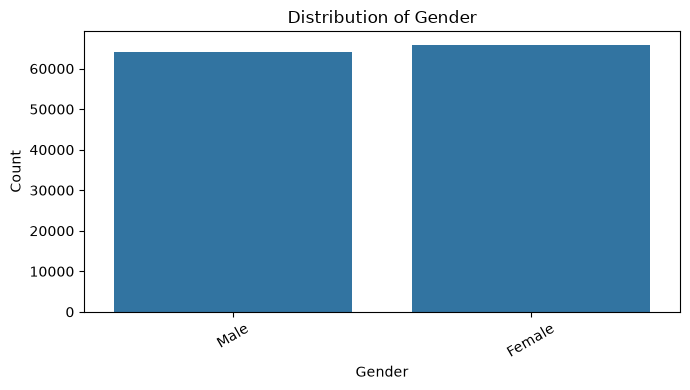

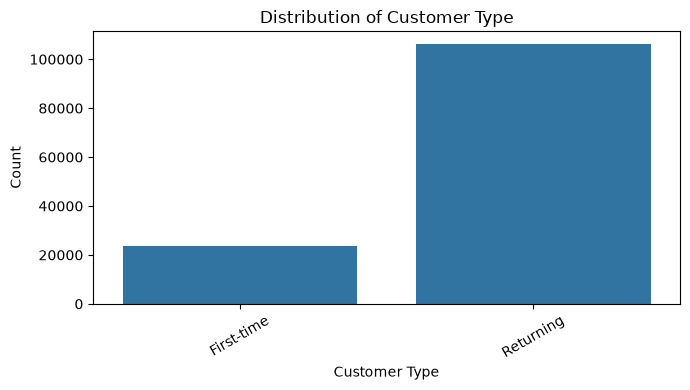

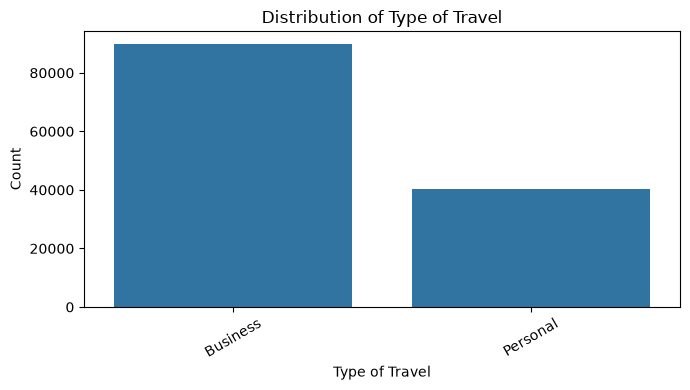

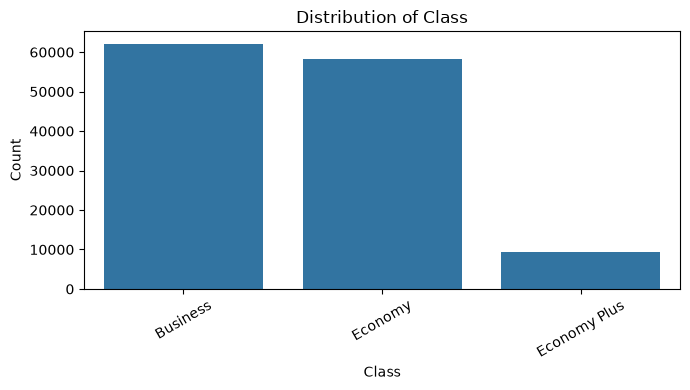

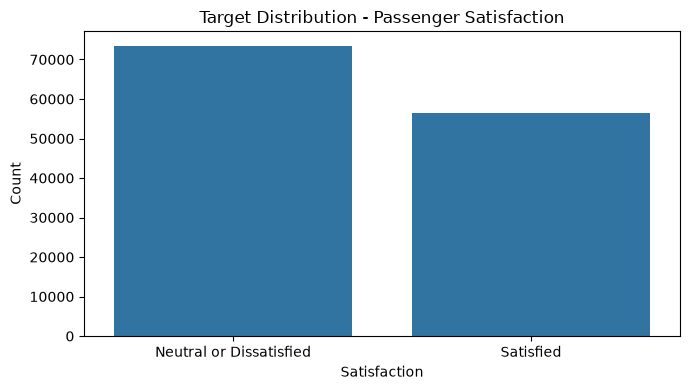

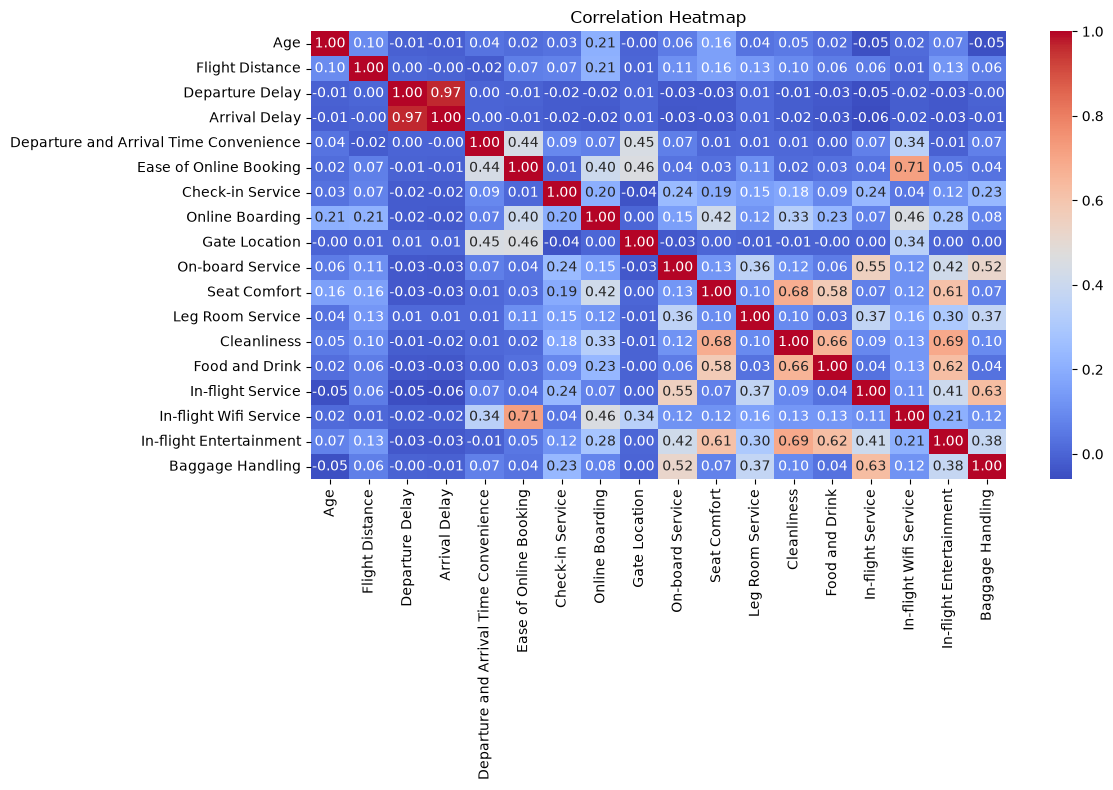

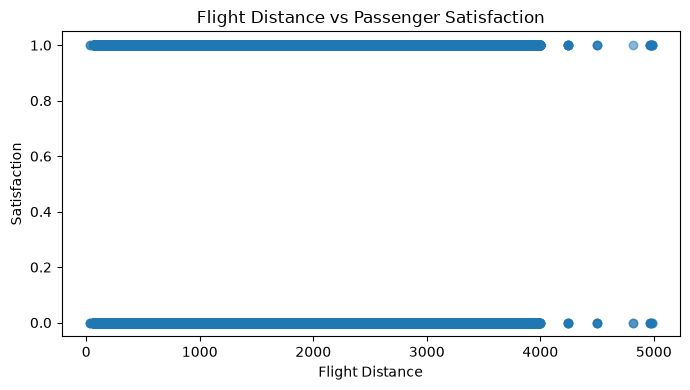

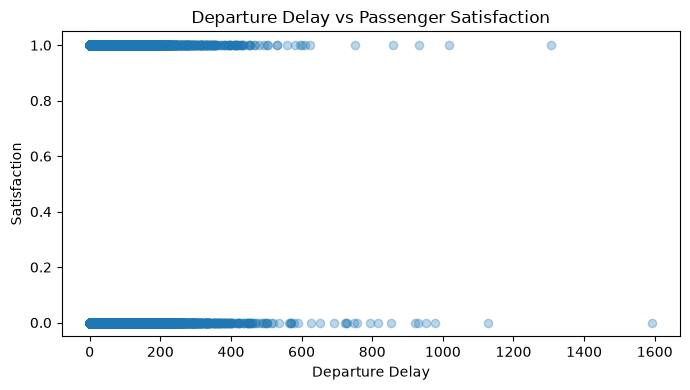

In [4]:
# Separate numerical and categorical features
numerical_features = df.select_dtypes(include=["int64", "float64"]).columns.tolist()

# Remove ID because it is an identifier, not a meaningful numerical feature
if "ID" in numerical_features:
    numerical_features.remove("ID")

# Explicitly select string/categorical features
categorical_features = df.select_dtypes(include=["str"]).columns.tolist()


# --------------------------------------------------
# Distribution plots for numerical features
# --------------------------------------------------

for column in numerical_features:

    plt.figure(figsize=(7, 4))

    # For delay variables, zoom into the main distribution
    if column in ["Departure Delay", "Arrival Delay"]:

        sns.histplot(
            df[column].dropna(),
            bins=40,
            kde=True
        )

        plt.xlim(0, 200)

        plt.title(f"Distribution of {column}")
        plt.xlabel(f"{column} (minutes)")
        plt.ylabel("Frequency")

    else:

        sns.histplot(
            df[column].dropna(),
            bins=30,
            kde=True
        )

        plt.title(f"Distribution of {column}")
        plt.xlabel(column)
        plt.ylabel("Frequency")

    plt.grid(
        axis="y",
        linestyle="--",
        alpha=0.4
    )

    plt.tight_layout()
    plt.show()


# --------------------------------------------------
# Distribution plots for categorical features
# --------------------------------------------------

for column in categorical_features:
    if column != "Satisfaction":
        plt.figure(figsize=(7, 4))
        sns.countplot(data=df, x=column)
        plt.title(f"Distribution of {column}")
        plt.xlabel(column)
        plt.ylabel("Count")
        plt.xticks(rotation=30)
        plt.tight_layout()
        plt.show()


# --------------------------------------------------
# Target distribution
# --------------------------------------------------

plt.figure(figsize=(7, 4))
sns.countplot(data=df, x="Satisfaction")
plt.title("Target Distribution - Passenger Satisfaction")
plt.xlabel("Satisfaction")
plt.ylabel("Count")
plt.tight_layout()
plt.show()


# --------------------------------------------------
# Correlation heatmap
# --------------------------------------------------

plt.figure(figsize=(12, 8))
sns.heatmap(
    df[numerical_features].corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()


# --------------------------------------------------
# Scatter plot 1: Flight Distance vs Satisfaction
# --------------------------------------------------

satisfaction_numeric = df["Satisfaction"].map({
    "Neutral or Dissatisfied": 0,
    "Satisfied": 1
})

plt.figure(figsize=(7, 4))
plt.scatter(
    df["Flight Distance"],
    satisfaction_numeric,
    alpha=0.3
)
plt.title("Flight Distance vs Passenger Satisfaction")
plt.xlabel("Flight Distance")
plt.ylabel("Satisfaction")
plt.tight_layout()
plt.show()


# --------------------------------------------------
# Scatter plot 2: Departure Delay vs Satisfaction
# --------------------------------------------------

plt.figure(figsize=(7, 4))
plt.scatter(
    df["Departure Delay"],
    satisfaction_numeric,
    alpha=0.3
)
plt.title("Departure Delay vs Passenger Satisfaction")
plt.xlabel("Departure Delay")
plt.ylabel("Satisfaction")
plt.tight_layout()
plt.show()

## A3 — Insight Commentary

### Observations

- **Feature distributions:** The distribution plots show the spread and frequency of the numerical and categorical features in the dataset.

- **Target distribution:** The target distribution shows the number of passengers belonging to the Satisfied and Neutral or Dissatisfied classes.

- **Correlation heatmap:** The heatmap shows the relationships between the numerical features and helps identify features with relatively stronger correlations.

- **Flight Distance vs Satisfaction:** The scatter plot shows how the two satisfaction classes are distributed across different flight distances.

- **Departure Delay vs Satisfaction:** The scatter plot shows how passenger satisfaction is distributed across different departure delay values.

# Section B — Preprocessing & Feature Engineering

## B1 — Data Cleaning

In [5]:
# ============================================================
# B1 — DATA CLEANING
# ============================================================

# Make a copy of the dataset before preprocessing
data = df.copy()

# ------------------------------------------------------------
# Remove duplicate rows
# ------------------------------------------------------------

print("Duplicate rows before removal:", data.duplicated().sum())

data = data.drop_duplicates()

print("Duplicate rows after removal:", data.duplicated().sum())


# ------------------------------------------------------------
# Remove ID column
# ------------------------------------------------------------

# ID is only an identifier and does not provide useful
# predictive information for passenger satisfaction

data = data.drop(columns=["ID"])


# ------------------------------------------------------------
# Handle missing values
# ------------------------------------------------------------

print("\nMissing values before treatment:")
print(data.isnull().sum()[data.isnull().sum() > 0])

# Fill missing Arrival Delay values with the median
# Median is less affected by extreme delay values

data["Arrival Delay"] = data["Arrival Delay"].fillna(
    data["Arrival Delay"].median()
)

print("\nMissing values after treatment:")
print(data.isnull().sum()[data.isnull().sum() > 0])


# ------------------------------------------------------------
# Check numerical outliers
# ------------------------------------------------------------

numerical_columns = data.select_dtypes(
    include=["int64", "float64"]
).columns

print("\nOutlier counts using the IQR method:")

for column in numerical_columns:

    Q1 = data[column].quantile(0.25)
    Q3 = data[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = (
        (data[column] < lower_bound) |
        (data[column] > upper_bound)
    ).sum()

    print(f"{column}: {outliers}")

Duplicate rows before removal: 0
Duplicate rows after removal: 0

Missing values before treatment:
Arrival Delay    393
dtype: int64

Missing values after treatment:
Series([], dtype: int64)

Outlier counts using the IQR method:
Age: 0
Flight Distance: 2855
Departure Delay: 18098
Arrival Delay: 17492
Departure and Arrival Time Convenience: 0
Ease of Online Booking: 0
Check-in Service: 16109
Online Boarding: 0
Gate Location: 0
On-board Service: 0
Seat Comfort: 0
Leg Room Service: 0
Cleanliness: 0
Food and Drink: 0
In-flight Service: 0
In-flight Wifi Service: 0
In-flight Entertainment: 0
Baggage Handling: 0


## B2 — Encoding, Scaling & Splitting

In [6]:
# ============================================================
# B2 — ENCODING, SCALING & SPLITTING
# ============================================================

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer


# ------------------------------------------------------------
# Separate features and target
# ------------------------------------------------------------

X = data.drop(columns=["Satisfaction"])

y = data["Satisfaction"].map({
    "Neutral or Dissatisfied": 0,
    "Satisfied": 1
})


# ------------------------------------------------------------
# Train-test split
# ------------------------------------------------------------

# 80% training and 20% testing
# Stratification maintains the same class distribution
# in both training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training set:", X_train.shape)
print("Testing set:", X_test.shape)


# ------------------------------------------------------------
# Identify numerical and categorical features
# ------------------------------------------------------------

numerical_features = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["str"]
).columns.tolist()

print("\nNumerical features:")
print(numerical_features)

print("\nCategorical features:")
print(categorical_features)


# ------------------------------------------------------------
# Handle outliers using training-set information
# ------------------------------------------------------------

# Calculate IQR bounds only from the training data
# to avoid data leakage

outlier_bounds = {}

for column in numerical_features:

    Q1 = X_train[column].quantile(0.25)
    Q3 = X_train[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outlier_bounds[column] = (
        lower_bound,
        upper_bound
    )


# Cap extreme values in both train and test sets
# using bounds calculated only from the training set

for column, (lower, upper) in outlier_bounds.items():

    X_train[column] = X_train[column].clip(
        lower=lower,
        upper=upper
    )

    X_test[column] = X_test[column].clip(
        lower=lower,
        upper=upper
    )


# ------------------------------------------------------------
# Create preprocessing pipeline
# ------------------------------------------------------------

preprocessor = ColumnTransformer(
    transformers=[
        (
            "numerical",
            StandardScaler(),
            numerical_features
        ),
        (
            "categorical",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            ),
            categorical_features
        )
    ]
)

print("\nPreprocessing setup completed.")

Training set: (103904, 22)
Testing set: (25976, 22)

Numerical features:
['Age', 'Flight Distance', 'Departure Delay', 'Arrival Delay', 'Departure and Arrival Time Convenience', 'Ease of Online Booking', 'Check-in Service', 'Online Boarding', 'Gate Location', 'On-board Service', 'Seat Comfort', 'Leg Room Service', 'Cleanliness', 'Food and Drink', 'In-flight Service', 'In-flight Wifi Service', 'In-flight Entertainment', 'Baggage Handling']

Categorical features:
['Gender', 'Customer Type', 'Type of Travel', 'Class']

Preprocessing setup completed.


## B3 — Feature Engineering

In [7]:
# ============================================================
# B3 — FEATURE ENGINEERING
# ============================================================

# Create a new feature representing the total delay
# experienced by the passenger

X_train["Total Delay"] = (
    X_train["Departure Delay"] +
    X_train["Arrival Delay"]
)

X_test["Total Delay"] = (
    X_test["Departure Delay"] +
    X_test["Arrival Delay"]
)

# Add the new feature to the numerical feature list
numerical_features.append("Total Delay")

print("New engineered feature: Total Delay")

print("\nUpdated numerical features:")
print(numerical_features)

New engineered feature: Total Delay

Updated numerical features:
['Age', 'Flight Distance', 'Departure Delay', 'Arrival Delay', 'Departure and Arrival Time Convenience', 'Ease of Online Booking', 'Check-in Service', 'Online Boarding', 'Gate Location', 'On-board Service', 'Seat Comfort', 'Leg Room Service', 'Cleanliness', 'Food and Drink', 'In-flight Service', 'In-flight Wifi Service', 'In-flight Entertainment', 'Baggage Handling', 'Total Delay']


### Feature Engineering Justification

The `Total Delay` feature is created by combining Departure Delay and Arrival Delay. It represents the overall delay experienced by a passenger and may provide additional information about passenger satisfaction compared with considering the two delay variables separately.

# Section D — Classification Track, Part A

## D1 — Classification Model Implementation

In [8]:
# ============================================================
# D1 — CLASSIFICATION MODEL IMPLEMENTATION
# ============================================================

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC

In [9]:
# ------------------------------------------------------------
# 1. Logistic Regression
# ------------------------------------------------------------

logistic_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

# Train the model
logistic_model.fit(X_train, y_train)

# Generate predictions
y_pred_lr = logistic_model.predict(X_test)

print("Logistic Regression predictions generated successfully.")

Logistic Regression predictions generated successfully.


In [10]:
# ------------------------------------------------------------
# 2. K-Nearest Neighbors
# ------------------------------------------------------------

knn_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", KNeighborsClassifier(
        n_neighbors=5
    ))
])

# Train the model
knn_model.fit(X_train, y_train)

# Generate predictions
y_pred_knn = knn_model.predict(X_test)

print("KNN predictions generated successfully.")

KNN predictions generated successfully.


In [11]:
# ------------------------------------------------------------
# 3. Gaussian Naive Bayes
# ------------------------------------------------------------

nb_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", GaussianNB())
])

# Train the model
nb_model.fit(X_train, y_train)

# Generate predictions
y_pred_nb = nb_model.predict(X_test)

print("Gaussian Naive Bayes predictions generated successfully.")

Gaussian Naive Bayes predictions generated successfully.


In [12]:
# ------------------------------------------------------------
# 4. Decision Tree Classifier
# ------------------------------------------------------------

dt_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", DecisionTreeClassifier(
        max_depth=10,
        random_state=42
    ))
])

# Train the model
dt_model.fit(X_train, y_train)

# Generate predictions
y_pred_dt = dt_model.predict(X_test)

print("Decision Tree predictions generated successfully.")

Decision Tree predictions generated successfully.


In [13]:
# ------------------------------------------------------------
# 5. Support Vector Classifier
# ------------------------------------------------------------

svc_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", SVC(
        C=1.0,
        kernel="linear",
        random_state=42
    ))
])

# Train the model
svc_model.fit(X_train, y_train)

# Generate predictions
y_pred_svc = svc_model.predict(X_test)

print("SVC predictions generated successfully.")

SVC predictions generated successfully.


## D2 — Model Evaluation

In [14]:
# ============================================================
# D2 — MODEL EVALUATION
# ============================================================

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    confusion_matrix
)

# Store predictions from all five models
model_predictions = {
    "Logistic Regression": y_pred_lr,
    "KNN": y_pred_knn,
    "Gaussian Naive Bayes": y_pred_nb,
    "Decision Tree": y_pred_dt,
    "SVC": y_pred_svc
}


# ------------------------------------------------------------
# Calculate Accuracy and Weighted F1 Score
# ------------------------------------------------------------

results = []

for model_name, predictions in model_predictions.items():

    accuracy = accuracy_score(
        y_test,
        predictions
    )

    weighted_f1 = f1_score(
        y_test,
        predictions,
        average="weighted"
    )

    results.append({
        "Model": model_name,
        "Accuracy": accuracy,
        "Weighted F1": weighted_f1
    })


# Create comparison table
comparison_table = pd.DataFrame(results)

comparison_table

# ------------------------------------------------------------
# Final preliminary comparison table
# ------------------------------------------------------------

comparison_table = comparison_table.sort_values(
    by="Weighted F1",
    ascending=False
).reset_index(drop=True)

comparison_table

,Model,Accuracy,Weighted F1
0,Decision Tree,0.946258,0.946125
1,KNN,0.930012,0.929711
2,SVC,0.878734,0.878319
3,Logistic Regression,0.877618,0.877340
4,Gaussian Naive Bayes,0.853403,0.853262


### Preliminary Observation

The five Part-A classification algorithms were trained using the same training and testing data. Accuracy and weighted F1-score are used to compare their classification performance, while confusion matrices show the correct and incorrect predictions for each model. The comparison table provides an initial comparison of the five algorithms.

# Section E — Classification Track, Part B

## E1 — Random Forest, AdaBoost and Gradient Boosting

In this section, three ensemble classification algorithms are implemented and evaluated using the same training and testing datasets as the Part A classifiers. Hyperparameter tuning is performed to identify suitable model configurations. Their performance is compared using accuracy, precision, recall, weighted F1-score and ROC-AUC, with confusion matrices used to examine classification errors.

In [15]:
# ============================================================
# E1 — REVIEW 2 CLASSIFICATION IMPORTS
# ============================================================

from sklearn.ensemble import (
    RandomForestClassifier,
    AdaBoostClassifier,
    GradientBoostingClassifier
)

from sklearn.model_selection import RandomizedSearchCV

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

from sklearn.pipeline import Pipeline

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [16]:
# ============================================================
# E2 — RANDOM FOREST CLASSIFIER
# ============================================================

# Step 1: Create the baseline Random Forest model

rf_baseline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=1
    ))
])

# Train the baseline model
rf_baseline.fit(X_train, y_train)

# Generate baseline predictions
y_pred_rf_baseline = rf_baseline.predict(X_test)

# Evaluate baseline weighted F1-score
rf_baseline_f1 = f1_score(
    y_test,
    y_pred_rf_baseline,
    average="weighted"
)

print("Baseline Random Forest Weighted F1:", rf_baseline_f1)

Baseline Random Forest Weighted F1: 0.9636640868456726


In [17]:
# Step 2: Define the Random Forest pipeline

rf_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        random_state=42,
        n_jobs=1
    ))
])

# Step 3: Define hyperparameters to test

rf_param_grid = {
    "classifier__n_estimators": [100, 150, 200],
    "classifier__max_depth": [None, 15, 25],
    "classifier__min_samples_split": [2, 5]
}

# Step 4: Perform hyperparameter tuning

rf_search = RandomizedSearchCV(
    estimator=rf_pipeline,
    param_distributions=rf_param_grid,
    n_iter=4,
    scoring="f1_weighted",
    cv=3,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

rf_search.fit(X_train, y_train)

# Step 5: Get the best model

rf_model = rf_search.best_estimator_

print("Best Random Forest Parameters:")
print(rf_search.best_params_)

print("\nBest Cross-Validation Weighted F1:")
print(rf_search.best_score_)

# Step 6: Generate test predictions

y_pred_rf = rf_model.predict(X_test)

print("\nTuned Random Forest Weighted F1:",
      f1_score(y_test, y_pred_rf, average="weighted"))

print("Weighted F1 Improvement:",
      f1_score(y_test, y_pred_rf, average="weighted")
      - rf_baseline_f1)

Fitting 3 folds for each of 4 candidates, totalling 12 fits
Best Random Forest Parameters:
{'classifier__n_estimators': 200, 'classifier__min_samples_split': 5, 'classifier__max_depth': None}

Best Cross-Validation Weighted F1:
0.9616166629653988

Tuned Random Forest Weighted F1: 0.9637416836927054
Weighted F1 Improvement: 7.759684703279035e-05


Random Forest Evaluation
------------------------
Accuracy: 0.9638127502309825
Precision (weighted): 0.9640207545265579
Recall (weighted): 0.9638127502309825
Weighted F1-score: 0.9637416836927054
ROC-AUC: 0.994489567428552


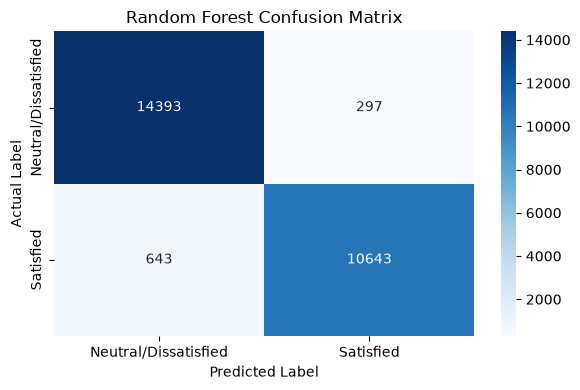

In [18]:
# ============================================================
# E3 — RANDOM FOREST EVALUATION
# ============================================================

rf_accuracy = accuracy_score(y_test, y_pred_rf)

rf_precision = precision_score(
    y_test, y_pred_rf, average="weighted", zero_division=0
)

rf_recall = recall_score(
    y_test, y_pred_rf, average="weighted", zero_division=0
)

rf_f1 = f1_score(
    y_test, y_pred_rf, average="weighted", zero_division=0
)

# ROC-AUC uses the probability of the positive class (Satisfied = 1)
rf_probabilities = rf_model.predict_proba(X_test)[:, 1]

rf_roc_auc = roc_auc_score(y_test, rf_probabilities)

print("Random Forest Evaluation")
print("------------------------")
print("Accuracy:", rf_accuracy)
print("Precision (weighted):", rf_precision)
print("Recall (weighted):", rf_recall)
print("Weighted F1-score:", rf_f1)
print("ROC-AUC:", rf_roc_auc)

# Confusion matrix
rf_cm = confusion_matrix(y_test, y_pred_rf)

plt.figure(figsize=(6, 4))
sns.heatmap(
    rf_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Neutral/Dissatisfied", "Satisfied"],
    yticklabels=["Neutral/Dissatisfied", "Satisfied"]
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Random Forest Confusion Matrix")
plt.tight_layout()
plt.show()

Top 15 Important Features:


,Feature,Importance
7,numerical__Online Boarding,0.167031
15,numerical__In-flight Wifi Service,0.142230
25,categorical__Class_Business,0.076065
23,categorical__Type of Travel_Business,0.064778
24,categorical__Type of Travel_Personal,0.056178
16,numerical__In-flight Entertainment,0.052242
10,numerical__Seat Comfort,0.044571
5,numerical__Ease of Online Booking,0.039693
26,categorical__Class_Economy,0.038528
11,numerical__Leg Room Service,0.030331


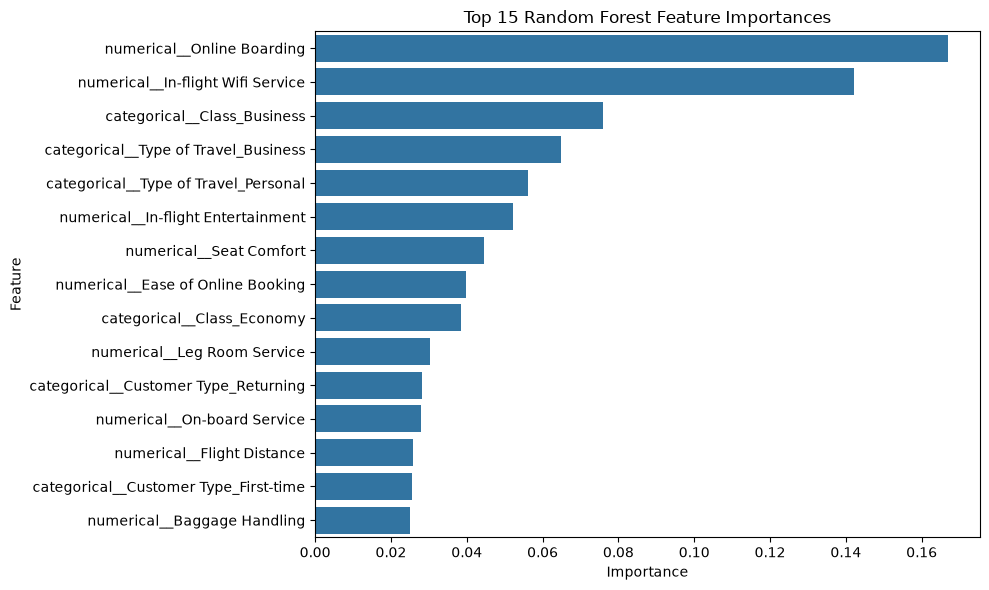

In [19]:
# ============================================================
# E4 — RANDOM FOREST FEATURE IMPORTANCE
# ============================================================

# Get the fitted preprocessor and classifier
rf_preprocessor = rf_model.named_steps["preprocessor"]
rf_classifier = rf_model.named_steps["classifier"]

# Get feature names after encoding
feature_names = rf_preprocessor.get_feature_names_out()

# Create a feature importance table
rf_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": rf_classifier.feature_importances_
})

rf_importance = rf_importance.sort_values(
    by="Importance",
    ascending=False
)

# Display the top 15 features
print("Top 15 Important Features:")
display(rf_importance.head(15))

# Plot feature importance
plt.figure(figsize=(10, 6))

sns.barplot(
    data=rf_importance.head(15),
    x="Importance",
    y="Feature"
)

plt.title("Top 15 Random Forest Feature Importances")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

## E5 — AdaBoost Classifier

AdaBoost (Adaptive Boosting) is an ensemble learning algorithm that combines multiple weak learners to create a stronger classifier. It gives greater attention to previously misclassified training examples so that subsequent learners can improve the predictions.

In this section, the number of estimators (`n_estimators`) and the learning rate (`learning_rate`) are tuned using cross-validation. The tuned model is evaluated using accuracy, weighted precision, weighted recall, weighted F1-score, ROC-AUC, and a confusion matrix.

In [20]:
# ============================================================
# E6 — ADABOOST BASELINE MODEL
# ============================================================

from sklearn.ensemble import AdaBoostClassifier

# Create the AdaBoost pipeline
ada_baseline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", AdaBoostClassifier(
        n_estimators=50,
        learning_rate=1.0,
        random_state=42
    ))
])

# Train the baseline model
ada_baseline.fit(X_train, y_train)

# Generate predictions
y_pred_ada_baseline = ada_baseline.predict(X_test)

# Calculate baseline weighted F1-score
ada_baseline_f1 = f1_score(
    y_test,
    y_pred_ada_baseline,
    average="weighted"
)

print("Baseline AdaBoost Weighted F1:", ada_baseline_f1)

Baseline AdaBoost Weighted F1: 0.9133308024549388


In [21]:
# ============================================================
# E7 — ADABOOST HYPERPARAMETER TUNING
# ============================================================

ada_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", AdaBoostClassifier(
        random_state=42
    ))
])

# Parameters to test
ada_param_grid = {
    "classifier__n_estimators": [50, 100, 150],
    "classifier__learning_rate": [0.5, 1.0, 1.5]
}

# Randomized hyperparameter search
ada_search = RandomizedSearchCV(
    estimator=ada_pipeline,
    param_distributions=ada_param_grid,
    n_iter=4,
    scoring="f1_weighted",
    cv=3,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

# Fit using the training data only
ada_search.fit(X_train, y_train)

# Store the best tuned model
ada_model = ada_search.best_estimator_

print("Best AdaBoost Parameters:")
print(ada_search.best_params_)

print("\nBest Cross-Validation Weighted F1:")
print(ada_search.best_score_)

# Predictions from the tuned model
y_pred_ada = ada_model.predict(X_test)

# Compare baseline and tuned F1-scores
ada_tuned_f1 = f1_score(
    y_test,
    y_pred_ada,
    average="weighted"
)

print("\nBaseline Weighted F1:", ada_baseline_f1)
print("Tuned Weighted F1:", ada_tuned_f1)
print("F1 Improvement:", ada_tuned_f1 - ada_baseline_f1)

Fitting 3 folds for each of 4 candidates, totalling 12 fits
Best AdaBoost Parameters:
{'classifier__n_estimators': 100, 'classifier__learning_rate': 1.5}

Best Cross-Validation Weighted F1:
0.9268912116545427

Baseline Weighted F1: 0.9133308024549388
Tuned Weighted F1: 0.9300361519119331
F1 Improvement: 0.01670534945699431


In [22]:
# ============================================================
# E8 — ADABOOST EVALUATION
# ============================================================

ada_accuracy = accuracy_score(y_test, y_pred_ada)

ada_precision = precision_score(
    y_test, y_pred_ada,
    average="weighted",
    zero_division=0
)

ada_recall = recall_score(
    y_test, y_pred_ada,
    average="weighted",
    zero_division=0
)

ada_f1 = f1_score(
    y_test, y_pred_ada,
    average="weighted",
    zero_division=0
)

# Probability for the positive class: Satisfied = 1
ada_probabilities = ada_model.predict_proba(X_test)[:, 1]

ada_roc_auc = roc_auc_score(
    y_test,
    ada_probabilities
)

print("AdaBoost Evaluation")
print("-------------------")
print("Accuracy:", ada_accuracy)
print("Precision (weighted):", ada_precision)
print("Recall (weighted):", ada_recall)
print("Weighted F1-score:", ada_f1)
print("ROC-AUC:", ada_roc_auc)

AdaBoost Evaluation
-------------------
Accuracy: 0.9300893132121959
Precision (weighted): 0.9300395577364985
Recall (weighted): 0.9300893132121959
Weighted F1-score: 0.9300361519119331
ROC-AUC: 0.978896358519088


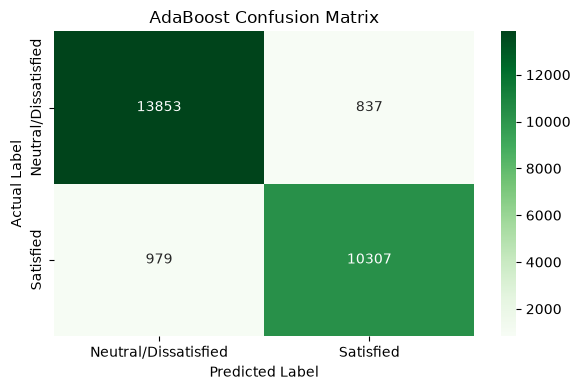

In [23]:
# ============================================================
# E9 — ADABOOST CONFUSION MATRIX
# ============================================================

ada_cm = confusion_matrix(y_test, y_pred_ada)

plt.figure(figsize=(6, 4))

sns.heatmap(
    ada_cm,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=["Neutral/Dissatisfied", "Satisfied"],
    yticklabels=["Neutral/Dissatisfied", "Satisfied"]
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("AdaBoost Confusion Matrix")
plt.tight_layout()
plt.show()

## E10 — Gradient Boosting Classifier

Gradient Boosting is an ensemble learning algorithm that builds decision trees sequentially. Each new tree attempts to correct errors made by the existing ensemble. The final prediction combines the contributions of the trees.

In this section, the Gradient Boosting Classifier is trained and tuned using cross-validation. Its performance is evaluated using accuracy, weighted precision, weighted recall, weighted F1-score, ROC-AUC, and a confusion matrix.

In [24]:
# ============================================================
# E11 — GRADIENT BOOSTING BASELINE
# ============================================================

from sklearn.ensemble import GradientBoostingClassifier

gb_baseline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", GradientBoostingClassifier(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=3,
        random_state=42
    ))
])

gb_baseline.fit(X_train, y_train)

y_pred_gb_baseline = gb_baseline.predict(X_test)

gb_baseline_f1 = f1_score(
    y_test,
    y_pred_gb_baseline,
    average="weighted"
)

print("Baseline Gradient Boosting Weighted F1:", gb_baseline_f1)

Baseline Gradient Boosting Weighted F1: 0.9430445844979816


In [25]:
# ============================================================
# E12 — GRADIENT BOOSTING HYPERPARAMETER TUNING
# ============================================================

gb_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", GradientBoostingClassifier(
        random_state=42
    ))
])

gb_param_grid = {
    "classifier__n_estimators": [100, 150, 200],
    "classifier__learning_rate": [0.05, 0.1, 0.2],
    "classifier__max_depth": [2, 3]
}

gb_search = RandomizedSearchCV(
    estimator=gb_pipeline,
    param_distributions=gb_param_grid,
    n_iter=4,
    scoring="f1_weighted",
    cv=3,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

gb_search.fit(X_train, y_train)

gb_model = gb_search.best_estimator_

print("Best Gradient Boosting Parameters:")
print(gb_search.best_params_)

print("\nBest Cross-Validation Weighted F1:")
print(gb_search.best_score_)

y_pred_gb = gb_model.predict(X_test)

gb_tuned_f1 = f1_score(
    y_test,
    y_pred_gb,
    average="weighted"
)

print("\nBaseline Weighted F1:", gb_baseline_f1)
print("Tuned Weighted F1:", gb_tuned_f1)
print("F1 Improvement:", gb_tuned_f1 - gb_baseline_f1)

Fitting 3 folds for each of 4 candidates, totalling 12 fits
Best Gradient Boosting Parameters:
{'classifier__n_estimators': 200, 'classifier__max_depth': 3, 'classifier__learning_rate': 0.05}

Best Cross-Validation Weighted F1:
0.9412382120005075

Baseline Weighted F1: 0.9430445844979816
Tuned Weighted F1: 0.9435025106643743
F1 Improvement: 0.0004579261663927303


In [26]:
# ============================================================
# E13 — GRADIENT BOOSTING EVALUATION
# ============================================================

gb_accuracy = accuracy_score(y_test, y_pred_gb)

gb_precision = precision_score(
    y_test, y_pred_gb,
    average="weighted",
    zero_division=0
)

gb_recall = recall_score(
    y_test, y_pred_gb,
    average="weighted",
    zero_division=0
)

gb_f1 = f1_score(
    y_test, y_pred_gb,
    average="weighted",
    zero_division=0
)

gb_probabilities = gb_model.predict_proba(X_test)[:, 1]

gb_roc_auc = roc_auc_score(
    y_test,
    gb_probabilities
)

print("Gradient Boosting Evaluation")
print("----------------------------")
print("Accuracy:", gb_accuracy)
print("Precision (weighted):", gb_precision)
print("Recall (weighted):", gb_recall)
print("Weighted F1-score:", gb_f1)
print("ROC-AUC:", gb_roc_auc)

Gradient Boosting Evaluation
----------------------------
Accuracy: 0.943601786264244
Precision (weighted): 0.943683269579282
Recall (weighted): 0.943601786264244
Weighted F1-score: 0.9435025106643743
ROC-AUC: 0.9878691975105575


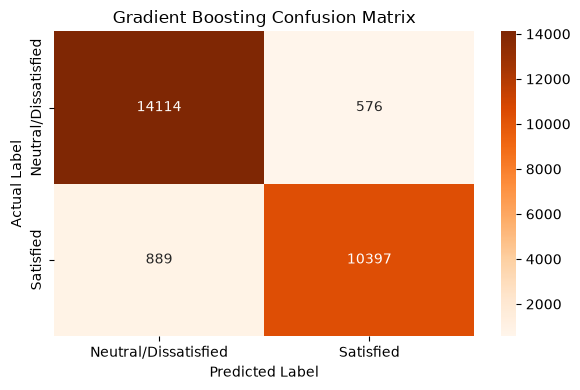

In [27]:
# ============================================================
# E14 — GRADIENT BOOSTING CONFUSION MATRIX
# ============================================================

gb_cm = confusion_matrix(y_test, y_pred_gb)

plt.figure(figsize=(6, 4))

sns.heatmap(
    gb_cm,
    annot=True,
    fmt="d",
    cmap="Oranges",
    xticklabels=["Neutral/Dissatisfied", "Satisfied"],
    yticklabels=["Neutral/Dissatisfied", "Satisfied"]
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Gradient Boosting Confusion Matrix")
plt.tight_layout()
plt.show()

## E15 — Bagging Classifier

Bagging (Bootstrap Aggregating) is an ensemble learning algorithm that trains many copies of the same base estimator on different bootstrap samples of the training data and combines their predictions by voting. Averaging over many high-variance learners reduces overfitting compared with a single model.

In this section, a Decision Tree is used as the base estimator, as required by the guidelines. The number of estimators (`n_estimators`), the fraction of training samples drawn for each estimator (`max_samples`), and the depth of the base Decision Tree (`max_depth`) are tuned using cross-validation. The tuned model is evaluated using accuracy, weighted precision, weighted recall, weighted F1-score, ROC-AUC, and a confusion matrix.

In [ ]:
# ============================================================
# E16 — BAGGING BASELINE MODEL
# ============================================================

from sklearn.ensemble import BaggingClassifier
from sklearn.tree import DecisionTreeClassifier

# Create the baseline Bagging pipeline
# A Decision Tree is used as the base estimator
bag_baseline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", BaggingClassifier(
        estimator=DecisionTreeClassifier(random_state=42),
        n_estimators=10,
        random_state=42,
        n_jobs=1
    ))
])

# Train the baseline model
bag_baseline.fit(X_train, y_train)

# Generate baseline predictions
y_pred_bag_baseline = bag_baseline.predict(X_test)

# Calculate baseline weighted F1-score
bag_baseline_f1 = f1_score(
    y_test,
    y_pred_bag_baseline,
    average="weighted"
)

print("Baseline Bagging Weighted F1:", bag_baseline_f1)


In [ ]:
# ============================================================
# E17 — BAGGING HYPERPARAMETER TUNING
# ============================================================

bag_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", BaggingClassifier(
        estimator=DecisionTreeClassifier(random_state=42),
        random_state=42,
        n_jobs=1
    ))
])

# Parameters to test
# estimator__max_depth controls the depth of the base Decision Tree
bag_param_grid = {
    "classifier__n_estimators": [10, 25, 50],
    "classifier__max_samples": [0.5, 0.8, 1.0],
    "classifier__estimator__max_depth": [None, 10]
}

# Randomized hyperparameter search
bag_search = RandomizedSearchCV(
    estimator=bag_pipeline,
    param_distributions=bag_param_grid,
    n_iter=4,
    scoring="f1_weighted",
    cv=3,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

# Fit using the training data only
bag_search.fit(X_train, y_train)

# Store the best tuned model
bag_model = bag_search.best_estimator_

print("Best Bagging Parameters:")
print(bag_search.best_params_)

print("\nBest Cross-Validation Weighted F1:")
print(bag_search.best_score_)

# Predictions from the tuned model
y_pred_bag = bag_model.predict(X_test)

# Compare baseline and tuned F1-scores
bag_tuned_f1 = f1_score(
    y_test,
    y_pred_bag,
    average="weighted"
)

print("\nBaseline Weighted F1:", bag_baseline_f1)
print("Tuned Weighted F1:", bag_tuned_f1)
print("F1 Improvement:", bag_tuned_f1 - bag_baseline_f1)


In [ ]:
# ============================================================
# E18 — BAGGING EVALUATION
# ============================================================

bag_accuracy = accuracy_score(y_test, y_pred_bag)

bag_precision = precision_score(
    y_test, y_pred_bag,
    average="weighted",
    zero_division=0
)

bag_recall = recall_score(
    y_test, y_pred_bag,
    average="weighted",
    zero_division=0
)

bag_f1 = f1_score(
    y_test, y_pred_bag,
    average="weighted",
    zero_division=0
)

# Probability for the positive class: Satisfied = 1
bag_probabilities = bag_model.predict_proba(X_test)[:, 1]

bag_roc_auc = roc_auc_score(
    y_test,
    bag_probabilities
)

print("Bagging Evaluation")
print("------------------")
print("Accuracy:", bag_accuracy)
print("Precision (weighted):", bag_precision)
print("Recall (weighted):", bag_recall)
print("Weighted F1-score:", bag_f1)
print("ROC-AUC:", bag_roc_auc)


In [ ]:
# ============================================================
# E19 — BAGGING CONFUSION MATRIX
# ============================================================

bag_cm = confusion_matrix(y_test, y_pred_bag)

plt.figure(figsize=(6, 4))

sns.heatmap(
    bag_cm,
    annot=True,
    fmt="d",
    cmap="Purples",
    xticklabels=["Neutral/Dissatisfied", "Satisfied"],
    yticklabels=["Neutral/Dissatisfied", "Satisfied"]
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Bagging Confusion Matrix")
plt.tight_layout()
plt.show()
